# 130 · Over-specialization on purpose, and the three-set diagnosis (train conditions / shifted conditions / replay)
Fine-tune MiniVLA v2 (flow expert) on only 25 demonstrations with a large LoRA rank, then ask three questions:
does it work on the exact training layouts, on the same layouts with the cubes nudged ~3 cm, and does an open-loop
replay of a training episode match the demonstration?

In [1]:
import os, numpy as np, torch, mujoco, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate, collect
from vlacourse.torch_data import TableTopDataset
from vlacourse.minivla import train_flow, MiniVLAFlowPolicy

SCENE, SEED = "single", 7
SMALL = os.path.abspath(f"../data/tabletop_{SCENE}_small25")
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
N_TRAIN, RANK, STEPS, H = 25, 64, 1500, 16
TRAIN_SEED0 = SEED * 100003            # collect() resets episode k with seed SEED*100003 + attempt (the expert never fails)

def shift_objects(env):
    for c in env.cube_colors:
        adr = env.model.jnt_qposadr[env.model.joint(f"cube_{c}").id]
        env.data.qpos[adr:adr + 2] += env.rng.normal(0, 0.03, 2)
    mujoco.mj_forward(env.model, env.data)

In [2]:
if not os.path.exists(os.path.join(SMALL, "meta.json")):
    collect(SMALL, N_TRAIN, seed=SEED, scene=SCENE, verbose=False)
ds = TableTopDataset(SMALL, horizon=H, use_images=False)
vla = train_flow(ds, rank=RANK, steps=STEPS, device=device, log_every=500)
print(f"{N_TRAIN} demos, LoRA rank {RANK}, {STEPS} steps")

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 19303.66it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


  step 500/1500 flow loss 0.418 (104s)


  step 1000/1500 flow loss 0.162 (213s)


  step 1500/1500 flow loss 0.070 (319s)
25 demos, LoRA rank 64, 1500 steps


In [3]:
env = TableTop(scene=SCENE, cameras=("front",), image_size=(128, 128), seed=0)
pol = MiniVLAFlowPolicy(vla, env, execute=8, steps=10, ds=ds)
train_cond = evaluate(env, pol, n_episodes=N_TRAIN, seed=TRAIN_SEED0)
shifted = evaluate(env, pol, n_episodes=N_TRAIN, seed=TRAIN_SEED0, on_reset=shift_objects)
fresh = evaluate(env, pol, n_episodes=N_TRAIN, seed=50_000)
for name, r in [("1) training initial conditions", train_cond), ("2) same scenes, objects moved ~3 cm", shifted), ("   fresh scenes", fresh)]:
    print(f"{name:40s} success {r['success']:.2f} CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}]")

1) training initial conditions           success 0.60 CI [0.41, 0.77]
2) same scenes, objects moved ~3 cm      success 0.32 CI [0.17, 0.52]
   fresh scenes                          success 0.08 CI [0.02, 0.25]


3) open-loop replay on a training episode: mean |predicted - demonstrated| next target, x/y/z [mm]: [ 4.8  5.5 24.3]


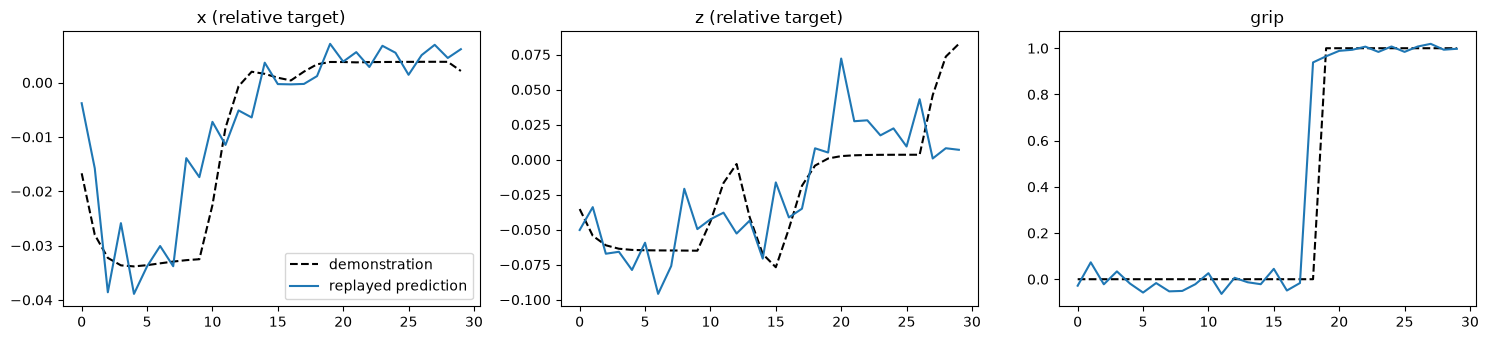

diagnosis: high (1) + clean replay (3) + collapse on (2) = over-specialization (memorized layouts), not a convention bug


In [4]:
e = ds.eps[0]; C = ds.episode_chunks(0)
pred = np.stack([vla.predict_chunk([e["front"][t]], [e["instruction"]], e["state"][t][None], steps=10)[0][0] for t in range(len(e["action"]))])
err_mm = np.abs(pred[:, :3] - C[:, 0, :3]).mean(0) * 1000
print("3) open-loop replay on a training episode: mean |predicted - demonstrated| next target, x/y/z [mm]:", err_mm.round(1))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for ax_, j, nm in zip(ax, [0, 2, 6], ["x (relative target)", "z (relative target)", "grip"]):
    ax_.plot(C[:, 0, j], "k--", label="demonstration"); ax_.plot(pred[:, j], label="replayed prediction"); ax_.set_title(nm)
ax[0].legend(); plt.tight_layout(); plt.show()
print("diagnosis: high (1) + clean replay (3) + collapse on (2) = over-specialization (memorized layouts), not a convention bug")

### Watch it: a training layout vs the same layout with the cubes nudged
Same policy, same layout, same instruction. Only the cubes moved a few centimetres.

In [5]:
from vlacourse import showcase as sc
sc.compare(env, {"exact training layout": pol, "same layout, cubes moved ~3 cm": pol}, seed=TRAIN_SEED0,
           per_policy_kw={"same layout, cubes moved ~3 cm": dict(on_reset=shift_objects)}, title="130 memorized vs nudged layout")

130 memorized vs nudged layout: exact training layout: success | same layout, cubes moved ~3 cm: failed


[True, False]